# Minimax Adaptive Positive Control with Nonnegative Disturbances

Two-state numerical experiment comparing adaptive CE control with a known-model baseline under the same disturbance realization.

## Experiment setting

Defines the system, initial interval, cost weights, horizon, disturbance range, and export settings.

In [2]:
%matplotlib inline

from pathlib import Path
import itertools

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np


A = np.array([[0.45, 0.20],
              [0.20, 0.50]])

s = np.ones(2)
r = 0.0
gamma = np.array([6.0, 6.0])

B_lower_0 = np.array([0.05, -0.80])
B_upper_0 = np.array([0.45,  0.10])
B_true = np.array([0.20, -0.40])

x0 = np.array([1.0, 0.7])
HORIZON = 70
DISTURBANCE_MAX = np.array([0.20, 0.20])

# Use None for a new disturbance realization on every run,
# or an integer for reproducibility.
# Generate the disturbances once and reuse them for both controllers.
SEED = None

# Enable only when TikZ .tex exports are needed.
EXPORT_TIKZ = False


## Controller and consistency update

| Function | Purpose |
|---|---|
| `interval_safe_bound` | Computes the input bound safe for every model in the interval. |
| `model_bound` | Computes the full bound for one known model. |
| `history_score` | Evaluates a candidate model's accumulated disturbance cost from the common history vector. |
| `ce_estimate` | Selects the CE endpoint and checks its score against the interval vertices. |
| `model_based_direction` | Computes the model-based feedback direction and cost vector. |
| `adaptive_gain` | Combines the CE direction with the current interval's safe bound. |
| `update_interval` | Intersects the interval with the latest observed transition constraint. |

In [3]:
def interval_safe_bound(B_lower, B_upper, tol=1e-12):
    """Largest componentwise E(C) from A >= |B| E(C), B in C."""
    beta = np.maximum(np.abs(B_lower), np.abs(B_upper))
    ratios = np.divide(
        A,
        beta[:, None],
        out=np.full_like(A, np.inf),
        where=beta[:, None] > tol,
    )
    E_safe = np.min(ratios, axis=0)
    if not np.all(np.isfinite(E_safe)):
        raise RuntimeError("The interval contains only the zero input channel.")
    return E_safe


def model_bound(B, tol=1e-12):
    """Model-specific saturation bound used only to find its CE direction."""
    ratios = np.divide(
        A,
        np.abs(B)[:, None],
        out=np.full_like(A, np.inf),
        where=np.abs(B)[:, None] > tol,
    )
    E_model = np.min(ratios, axis=0)
    if not np.all(np.isfinite(E_model)):
        raise RuntimeError("The selected model has no input channel.")
    return E_model


def history_score(B, Z):
    Z_v, Z_x, Z_u = Z[:2], Z[2:4], Z[4]
    return gamma @ (Z_v - A @ Z_x - B * Z_u)


def ce_estimate(B_lower, B_upper, Z, tol=1e-12):
    """Exact minimizer of the affine score over the current interval."""
    B_hat = B_upper.copy() if Z[4] >= -tol else B_lower.copy()
    corners = [
        np.array(corner)
        for corner in itertools.product(*zip(B_lower, B_upper))
    ]
    assert history_score(B_hat, Z) <= min(
        history_score(B, Z) for B in corners
    ) + 1e-9
    return B_hat


def model_based_direction(B, x):
    """Return the optimal saturated direction Lambda*(B) in {-1,+1}."""
    E_model = model_bound(B)
    candidates = []
    for direction in (-1, 1):
        K = direction * E_model
        closed_loop = A + np.outer(B, K)
        if np.min(closed_loop) < -1e-12:
            continue
        if max(abs(np.linalg.eigvals(closed_loop))) >= 1 - 1e-12:
            continue
        p = np.linalg.solve(np.eye(2) - closed_loop.T, s + r * K)
        if direction * (r + B @ p) <= 1e-10:
            candidates.append((p @ x, direction, p, E_model))
    if not candidates:
        raise RuntimeError("No admissible model-based direction was found.")
    _, direction, p, E_model = min(candidates, key=lambda item: item[0])
    return direction, p, E_model


def adaptive_gain(B_hat, B_lower, B_upper, x):
    """Use the CE direction and the safe magnitude determined by C_t."""
    direction, p, E_model = model_based_direction(B_hat, x)
    E_safe = interval_safe_bound(B_lower, B_upper)
    K = direction * E_safe
    beta = np.maximum(np.abs(B_lower), np.abs(B_upper))
    assert np.all(A + 1e-12 >= np.outer(beta, E_safe))
    assert np.all(A + np.outer(B_hat, K) >= -1e-12)
    assert max(abs(np.linalg.eigvals(A + np.outer(B_hat, K)))) < 1
    return K, p, E_safe, E_model, direction


def update_interval(B_lower, B_upper, x, u, v, tol=1e-12):
    """Intersect the current interval with the latest transition constraint."""
    if u > tol:
        B_upper = np.minimum(B_upper, (v - A @ x) / u)
    elif u < -tol:
        B_lower = np.maximum(B_lower, (v - A @ x) / u)
    else:
        assert np.all(v + 1e-12 >= A @ x)
    if np.any(B_lower > B_upper + 1e-10):
        raise RuntimeError("The consistency interval became empty.")
    return B_lower, B_upper


## Disturbances and simulation

| Function | Purpose |
|---|---|
| `disturbance` | Returns a sample from the shared disturbance sequence. |
| `simulate_ce` | Simulates adaptive control and updates the interval and history. |
| `simulate_known_B` | Simulates the baseline using the true input vector. |

In [4]:
def disturbance(t):
    """Return the shared disturbance sample at time t."""
    return disturbance_sequence[t].copy()


def simulate_ce(horizon=HORIZON):
    """Simulate the adaptive CE controller and interval recursion."""
    x = x0.copy()
    B_lower, B_upper = B_lower_0.copy(), B_upper_0.copy()
    Z = np.zeros(5)
    rows = []
    true_residual_sum = np.zeros(2)
    for t in range(horizon):
        B_hat = ce_estimate(B_lower, B_upper, Z)
        K, p, E_safe, E_model, direction = adaptive_gain(
            B_hat, B_lower, B_upper, x
        )
        u = float(K @ x)
        w = disturbance(t)
        v = A @ x + B_true * u + w
        lower_before, upper_before = B_lower.copy(), B_upper.copy()
        B_lower, B_upper = update_interval(B_lower, B_upper, x, u, v)
        assert np.all(B_lower <= B_true + 1e-10)
        assert np.all(B_true <= B_upper + 1e-10)
        assert np.all(v >= -1e-12) and np.all(w >= -1e-12)
        true_residual_sum += v - A @ x - B_true * u
        rows.append(
            dict(
                t=t,
                x=x.copy(),
                u=u,
                w=w.copy(),
                v=v.copy(),
                B_hat=B_hat.copy(),
                B_lower=lower_before,
                B_upper=upper_before,
                E_safe=E_safe.copy(),
                E_model=E_model.copy(),
                p=p.copy(),
                gain_direction=direction,
                score=history_score(B_hat, Z),
            )
        )
        Z += np.r_[v, x, u]
        assert np.isclose(history_score(B_true, Z), gamma @ true_residual_sum)
        x = v
    return rows, B_lower, B_upper, Z


def simulate_known_B(horizon=HORIZON):
    """Simulate the benchmark controller that knows B_true."""
    x, rows = x0.copy(), []
    for t in range(horizon):
        direction, _, E_true = model_based_direction(B_true, x)
        K = direction * E_true
        u, w = float(K @ x), disturbance(t)
        rows.append(dict(t=t, x=x.copy(), u=u))
        x = A @ x + B_true * u + w
    return rows


## Plotting and export

| Function | Purpose |
|---|---|
| `values` | Extracts a recorded quantity or one of its components. |
| `fix_tikzplotlib_legend` | Applies compatibility fixes for TikZ export. |
| `draw_panel` | Draws one of the six manuscript panels. |
| `build_figure` | Arranges the panels in a two-row figure. |
| `save_combined_figure` | Saves the combined figure as PDF and PNG. |
| `export_tikz_panels` | Exports the individual panels and combined layout as TikZ files. |

In [5]:
def values(rows, key, component=None):
    """Stack one recorded scalar, vector, or selected component."""
    data = [row[key] if component is None else row[key][component] for row in rows]
    return np.asarray(data)


def fix_tikzplotlib_legend(obj):
    """Compatibility fixes for recent Matplotlib versions."""
    if hasattr(obj, "_ncols"):
        obj._ncol = obj._ncols
    if isinstance(obj, mpl.lines.Line2D) and not hasattr(obj, "_us_dashSeq"):
        obj._us_dashOffset, obj._us_dashSeq = obj._unscaled_dash_pattern
    for child in obj.get_children():
        fix_tikzplotlib_legend(child)


def draw_panel(axis, panel, ce_run, known_run):
    """Draw one of the six panels used in the paper."""
    t = values(ce_run, "t")
    blue, orange, green = "#0072B2", "#D55E00", "#009E73"
    if panel in (0, 1):
        i = panel
        axis.plot(
            t, values(ce_run, "x", i), color=blue, lw=1.5,
            marker="o", ms=3, label="Adaptive",
        )
        axis.plot(
            t, values(known_run, "x", i), "--", color=orange, lw=1.5,
            marker="s", ms=3, label="Known model",
        )
        axis.set_ylabel(fr"$x_{{{i + 1},t}}$")
    elif panel == 2:
        axis.plot(
            t, values(ce_run, "u"), color=blue, lw=1.5,
            marker="o", ms=3, label="Adaptive",
        )
        axis.plot(
            t, values(known_run, "u"), "--", color=orange, lw=1.5,
            marker="s", ms=3, label="Known model",
        )
        axis.set_ylabel(r"$u_t$")
    elif panel == 3:
        E_true = model_bound(B_true)
        axis.step(
            t, values(ce_run, "E_safe", 0), where="post", color=blue,
            lw=1.5, marker="o", ms=3, label=r"$E_1(\mathcal{C}_t)$",
        )
        axis.step(
            t, values(ce_run, "E_safe", 1), where="post", color=orange,
            lw=1.5, marker="s", ms=3, label=r"$E_2(\mathcal{C}_t)$",
        )
        axis.axhline(
            E_true[0], color=blue, ls="--", lw=1.5,
            label=r"$E_1(\{B_\star\})$",
        )
        axis.axhline(
            E_true[1], color=orange, ls="--", lw=1.5,
            label=r"$E_2(\{B_\star\})$",
        )
        axis.set_ylabel(r"$E(\mathcal{C}_t)$")
    else:
        i = panel - 4
        lower = values(ce_run, "B_lower", i)
        upper = values(ce_run, "B_upper", i)
        estimate = values(ce_run, "B_hat", i)
        axis.fill_between(t, lower, upper, color=blue, alpha=0.15, label="Interval")
        axis.plot(t, lower, color=blue, lw=1.0, marker=".", ms=2)
        axis.plot(t, upper, color=blue, lw=1.0, marker=".", ms=2)
        axis.step(
            t, estimate, where="post", color=green, lw=1.5,
            marker="o", ms=3, label="CE estimate",
        )
        axis.axhline(B_true[i], color=orange, ls="--", lw=1.5, label="True value")
        axis.set_ylabel(fr"$B_{{{i + 1}}}$")
    axis.set_xlabel(r"$t$")
    axis.grid(True, which="both", alpha=0.35)
    axis.legend(
        loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2,
        frameon=False, fontsize=8,
    )


def build_figure(ce_run, known_run):
    """Build and return the combined six-panel Matplotlib figure."""
    fig, axes = plt.subplots(2, 3, figsize=(12.2, 7.6), sharex=True)
    for panel, axis in enumerate(axes.ravel()):
        draw_panel(axis, panel, ce_run, known_run)
    fig.subplots_adjust(wspace=0.32, hspace=0.72)
    return fig


def save_combined_figure(fig):
    """Save the combined figure in PDF and PNG formats."""
    fig.savefig("interval_B_vector_ce_simulation.pdf", bbox_inches="tight")
    fig.savefig(
        "interval_B_vector_ce_simulation.png",
        dpi=220,
        bbox_inches="tight",
    )


def export_tikz_panels(ce_run, known_run):
    """Export the individual panels and combined layout as TikZ files."""
    try:
        import tikzplotlib
    except ImportError as exc:
        raise ImportError(
            "TikZ export requires tikzplotlib. Install it or set "
            "EXPORT_TIKZ = False."
        ) from exc

    figure_dir = Path("figures")
    figure_dir.mkdir(exist_ok=True)
    panel_files = [
        "state_x1.tex",
        "state_x2.tex",
        "control_input.tex",
        "adaptive_bound.tex",
        "interval_B1.tex",
        "interval_B2.tex",
    ]

    combined = build_figure(ce_run, known_run)
    fix_tikzplotlib_legend(combined)
    tikzplotlib.save(
        str(figure_dir / "interval_B_vector_ce_all_panels.tex"),
        figure=combined,
    )
    plt.close(combined)

    for panel, filename in enumerate(panel_files):
        panel_fig, panel_ax = plt.subplots(figsize=(3.4, 2.35))
        draw_panel(panel_ax, panel, ce_run, known_run)
        panel_fig.tight_layout()
        fix_tikzplotlib_legend(panel_fig)
        tikzplotlib.save(
            str(figure_dir / filename),
            figure=panel_fig,
            axis_width=r"\linewidth",
            axis_height=r"0.58\linewidth",
        )
        plt.close(panel_fig)
    return panel_files


##  Run and verify

Generates a fresh seed and shared disturbances when `SEED = None`, runs both controllers, and checks the results. After the initial setup, rerun this cell and the next code cell for a new realization. Set `SEED` to a printed seed to reproduce a run.

In [6]:
run_seed = SEED if SEED is not None else int(np.random.SeedSequence().generate_state(1)[0])
rng = np.random.default_rng(run_seed)
disturbance_sequence = rng.uniform(
    low=np.zeros(2), high=DISTURBANCE_MAX, size=(HORIZON, 2)
)

open_loop_radius = float(np.max(np.abs(np.linalg.eigvals(A))))
assert open_loop_radius < 1.0, "The manuscript's A should be Schur stable."

ce_run, B_lower_T, B_upper_T, Z_T = simulate_ce(HORIZON)
known_run = simulate_known_B(HORIZON)

E_history = values(ce_run, "E_safe")
E_final = interval_safe_bound(B_lower_T, B_upper_T)

assert np.all(np.diff(E_history, axis=0) >= -1e-12)
assert np.all(B_lower_T <= B_true + 1e-12)
assert np.all(B_true <= B_upper_T + 1e-12)

print("spectral radius rho(A) =", round(open_loop_radius, 4))
print("noise seed             =", run_seed)
print("initial E(C_0)         =", np.round(E_history[0], 4))
print("known-model E({B*})    =", np.round(model_bound(B_true), 4))
print("final E(C_T)           =", np.round(E_final, 4))
print("final lower bound      =", np.round(B_lower_T, 4))
print("true B                 =", B_true)
print("final upper bound      =", np.round(B_upper_T, 4))
print("first six directions   =", values(ce_run, "gain_direction")[:6])

spectral radius rho(A) = 0.6766
noise seed             = 3593499089
initial E(C_0)         = [0.25   0.4444]
known-model E({B*})    = [0.5 1. ]
final E(C_T)           = [0.3975 0.9091]
final lower bound      = [ 0.159  -0.5031]
true B                 = [ 0.2 -0.4]
final upper bound      = [ 0.22   -0.3905]
first six directions   = [-1  1 -1  1 -1  1]


## Display and save

Displays the six-panel figure and exports the PDF, PNG, and TikZ files.

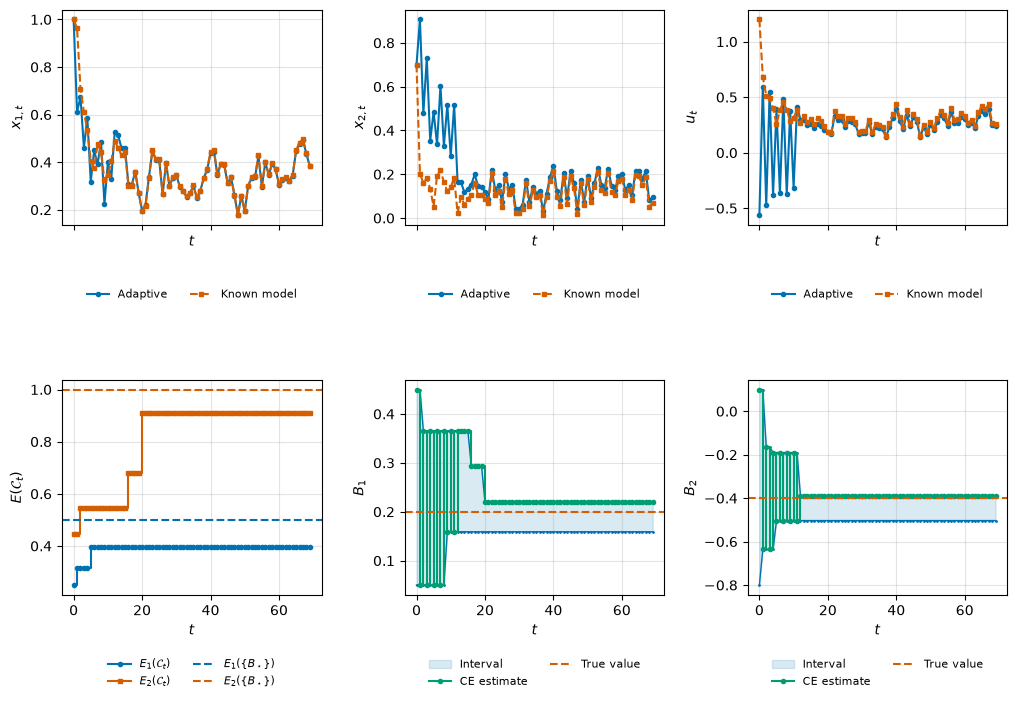

Saved interval_B_vector_ce_simulation.pdf
Saved interval_B_vector_ce_simulation.png
Exported TikZ panels:
  figures/state_x1.tex
  figures/state_x2.tex
  figures/control_input.tex
  figures/adaptive_bound.tex
  figures/interval_B1.tex
  figures/interval_B2.tex


In [7]:
fig = build_figure(ce_run, known_run)
save_combined_figure(fig)
plt.show()

print("Saved interval_B_vector_ce_simulation.pdf")
print("Saved interval_B_vector_ce_simulation.png")

EXPORT_TIKZ = True
if EXPORT_TIKZ:
    panel_files = export_tikz_panels(ce_run, known_run)
    print("Exported TikZ panels:")
    for filename in panel_files:
        print("  figures/" + filename)
else:
    print("TikZ export skipped. Set EXPORT_TIKZ = True to enable it.")